In [1]:
import os
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

X_train, y_train, X_test, y_test = joblib.load("../data/processed/data_processed.joblib")
print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Part d'attaques - train :", round(y_train.mean(), 3), "| test :", round(y_test.mean(), 3))

Train : (175341, 60) | Test : (82332, 60)
Part d'attaques - train : 0.681 | test : 0.551


In [2]:
resultats = []  
os.makedirs("../docs/figures", exist_ok=True)


def evaluer(nom, modele, duree_entrainement=None):
    """Évalue un modèle sur le jeu de test et ajoute une ligne au tableau comparatif."""
    pred = modele.predict(X_test)
    if hasattr(modele, "predict_proba"):
        score = modele.predict_proba(X_test)[:, 1]
    elif hasattr(modele, "decision_function"):
        score = modele.decision_function(X_test)
    else:
        score = pred

    ligne = {
        "Modèle": nom,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, score),
    }
    if duree_entrainement is not None:
        ligne["Temps (s)"] = round(duree_entrainement, 1)

    resultats[:] = [r for r in resultats if r["Modèle"] != nom]  # évite les doublons si on relance
    resultats.append(ligne)
    return pred, score


def afficher_matrice(nom, pred):
    """Dessine et enregistre la matrice de confusion."""
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Normal", "Attaque"], cmap="Blues", values_format="d"
    )
    plt.title(f"Matrice de confusion - {nom}")
    plt.savefig(f"../docs/figures/matrice_{nom.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    plt.show()

Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
Zero-R    0.5506     0.5506     1.0 0.7102      0.5        0.1


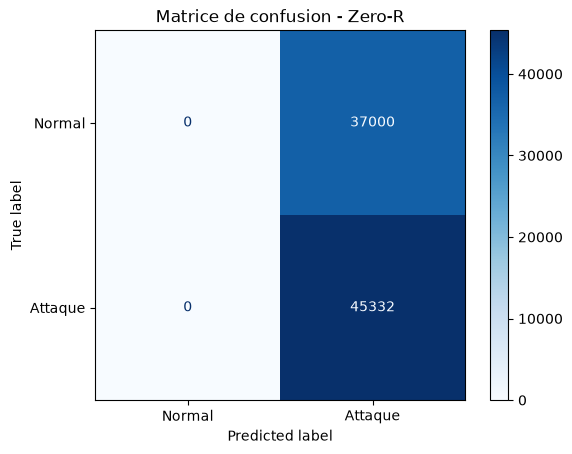

In [3]:
from sklearn.dummy import DummyClassifier

debut = time.time()
zero_r = DummyClassifier(strategy="most_frequent")
zero_r.fit(X_train, y_train)
pred, score = evaluer("Zero-R", zero_r, time.time() - debut)

print(pd.DataFrame(resultats).round(4).to_string(index=False))
afficher_matrice("Zero-R", pred)

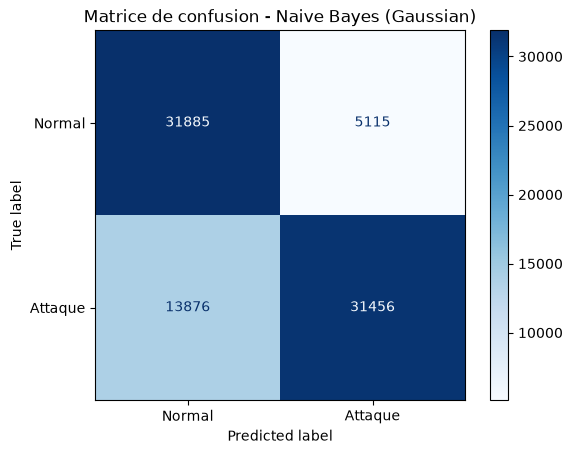

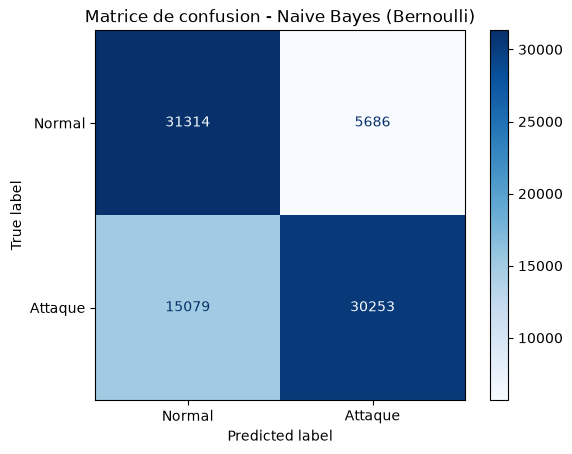

                 Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
                 Zero-R    0.5506     0.5506  1.0000 0.7102   0.5000        0.1
 Naive Bayes (Gaussian)    0.7693     0.8601  0.6939 0.7681   0.8698        0.2
Naive Bayes (Bernoulli)    0.7478     0.8418  0.6674 0.7445   0.8173        0.1


In [4]:
from sklearn.naive_bayes import BernoulliNB, GaussianNB

debut = time.time()
nb_gauss = GaussianNB()
nb_gauss.fit(X_train, y_train)
pred, score = evaluer("Naive Bayes (Gaussian)", nb_gauss, time.time() - debut)
afficher_matrice("Naive Bayes (Gaussian)", pred)

debut = time.time()
nb_bern = BernoulliNB(alpha=1.0)  # alpha = 1 : lissage de Laplace
nb_bern.fit(X_train, y_train)
pred, score = evaluer("Naive Bayes (Bernoulli)", nb_bern, time.time() - debut)
afficher_matrice("Naive Bayes (Bernoulli)", pred)

print(pd.DataFrame(resultats).round(4).to_string(index=False))

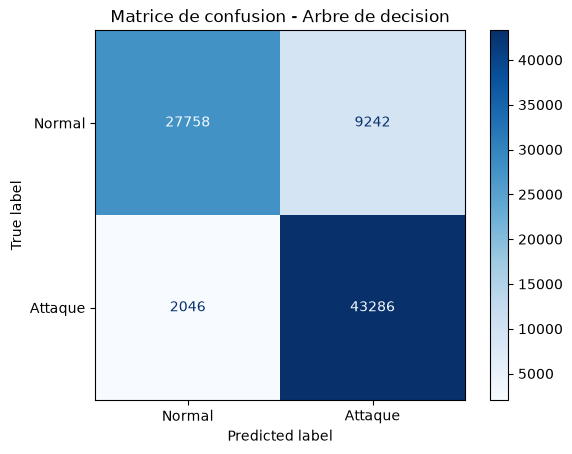

Profondeur : 42 | Feuilles : 5699
Accuracy train : 0.9982 | test : 0.8629
                 Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
                 Zero-R    0.5506     0.5506  1.0000 0.7102   0.5000        0.1
 Naive Bayes (Gaussian)    0.7693     0.8601  0.6939 0.7681   0.8698        0.2
Naive Bayes (Bernoulli)    0.7478     0.8418  0.6674 0.7445   0.8173        0.1
      Arbre de decision    0.8629     0.8241  0.9549 0.8847   0.8550        2.6


In [5]:
from sklearn.tree import DecisionTreeClassifier

debut = time.time()
arbre = DecisionTreeClassifier(criterion="gini", random_state=42)  # sans limite de profondeur
arbre.fit(X_train, y_train)
duree = time.time() - debut
pred, score = evaluer("Arbre de decision", arbre, duree)
afficher_matrice("Arbre de decision", pred)

print("Profondeur :", arbre.get_depth(), "| Feuilles :", arbre.get_n_leaves())
print("Accuracy train :", round(arbre.score(X_train, y_train), 4),
      "| test :", round(arbre.score(X_test, y_test), 4))
print(pd.DataFrame(resultats).round(4).to_string(index=False))

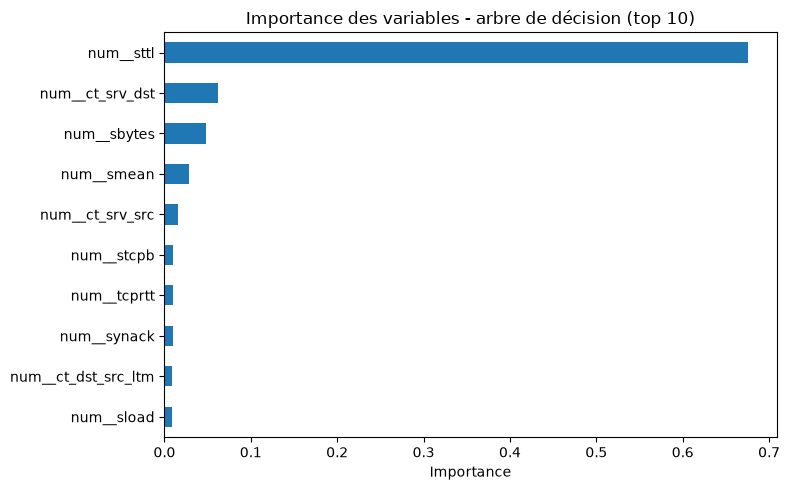

In [6]:
preprocesseur = joblib.load("../models/preprocessor.joblib")
noms = preprocesseur.get_feature_names_out()
importances = pd.Series(arbre.feature_importances_, index=noms).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
importances[::-1].plot(kind="barh", color="#1f77b4")
plt.title("Importance des variables - arbre de décision (top 10)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("../docs/figures/importance_arbre.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame(resultats).round(4).to_csv("../docs/resultats_modeles.csv", index=False)

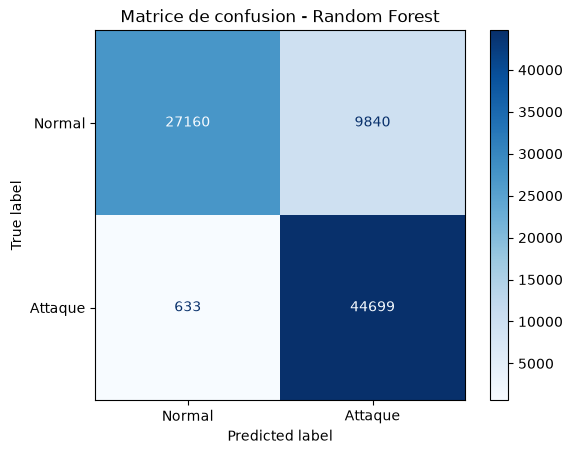

Accuracy train : 0.9982 | test : 0.8728
                 Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
                 Zero-R    0.5506     0.5506  1.0000 0.7102   0.5000        0.1
 Naive Bayes (Gaussian)    0.7693     0.8601  0.6939 0.7681   0.8698        0.2
Naive Bayes (Bernoulli)    0.7478     0.8418  0.6674 0.7445   0.8173        0.1
      Arbre de decision    0.8629     0.8241  0.9549 0.8847   0.8550        2.6
          Random Forest    0.8728     0.8196  0.9860 0.8951   0.9796       19.3


In [7]:
from sklearn.ensemble import RandomForestClassifier

debut = time.time()
foret = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
foret.fit(X_train, y_train)
duree = time.time() - debut
pred, score = evaluer("Random Forest", foret, duree)
afficher_matrice("Random Forest", pred)

print("Accuracy train :", round(foret.score(X_train, y_train), 4),
      "| test :", round(foret.score(X_test, y_test), 4))
print(pd.DataFrame(resultats).round(4).to_string(index=False))

pd.DataFrame(resultats).round(4).to_csv("../docs/resultats_modeles.csv", index=False)

In [8]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(X_train, y_train)

debut = time.time()
_ = knn.predict_proba(X_test[:2000])
t_2000 = time.time() - debut
print(f"2000 lignes : {t_2000:.1f} s")
print(f"Estimation pour {len(X_test)} lignes : {t_2000 * len(X_test) / 2000 / 60:.1f} min")

2000 lignes : 1.1 s
Estimation pour 82332 lignes : 0.8 min


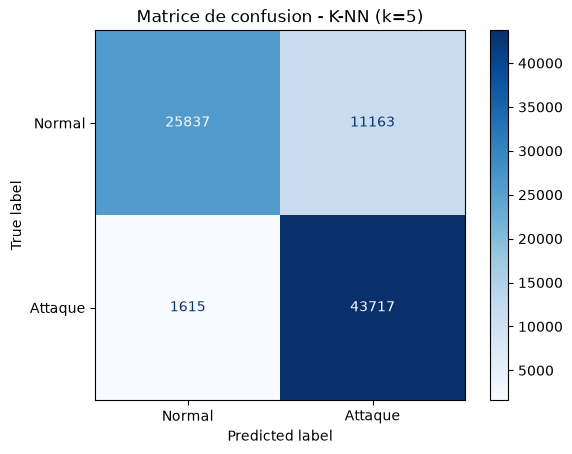

                 Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
                 Zero-R    0.5506     0.5506  1.0000 0.7102   0.5000        0.1
 Naive Bayes (Gaussian)    0.7693     0.8601  0.6939 0.7681   0.8698        0.2
Naive Bayes (Bernoulli)    0.7478     0.8418  0.6674 0.7445   0.8173        0.1
      Arbre de decision    0.8629     0.8241  0.9549 0.8847   0.8550        2.6
          Random Forest    0.8728     0.8196  0.9860 0.8951   0.9796       19.3
             K-NN (k=5)    0.8448     0.7966  0.9644 0.8725   0.9315       41.7


In [9]:
def evaluer_scores(nom, pred, score, duree=None):
    """Comme evaluer(), mais à partir de scores déjà calculés (évite de refaire les voisins deux fois)."""
    ligne = {
        "Modèle": nom,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, score),
    }
    if duree is not None:
        ligne["Temps (s)"] = round(duree, 1)
    resultats[:] = [r for r in resultats if r["Modèle"] != nom]
    resultats.append(ligne)


debut = time.time()
score = knn.predict_proba(X_test)[:, 1]
pred = (score >= 0.5).astype(int)
duree = time.time() - debut

evaluer_scores("K-NN (k=5)", pred, score, duree)
afficher_matrice("K-NN (k=5)", pred)

print(pd.DataFrame(resultats).round(4).to_string(index=False))
pd.DataFrame(resultats).round(4).to_csv("../docs/resultats_modeles.csv", index=False)